In [1]:
import jax.numpy as jnp
import jax

In [2]:
import networkx as nx
import matplotlib.pyplot as plt
from plotly.subplots import make_subplots
from matplotlib.animation import FuncAnimation
from netgraph import Graph
from networkx.drawing.nx_pydot import graphviz_layout
import math

In [3]:
import numpy as np
import random

In [4]:
map = {'0': '(',
       '1': ')'
      }

### Helper function

In [5]:
def show_graph_with_labels(adjacency_matrix, n_leaves, leaf_info = None, return_img = False):
    '''
      Shows the tree with label names. Adds distinct colors to the leave nodes and the ancestors of the leave nodes.

      Args:
        adjacency_matrix: adjacency matrix of the tree
        n_leaves: number of leaves in the tree
      Returns:
        None
    '''
    label_names = {}
    leaf_ids = []

    if(leaf_info != None):
        label_names = leaf_info[0]
        leaf_ids = leaf_info[1]
    else:
        # if label_names not provided, assuming perfect binary tree
        # assert n_leaves == 2**int(math.log2(n_leaves))

        for i in range(0,adjacency_matrix.shape[0]):
            label_names[i] = str(i)

        for i in range(0,n_leaves):
            leaf_ids.append(i)

    rows, cols = np.where(adjacency_matrix == 1)
    edges = zip(rows.tolist(), cols.tolist())


    gr = nx.DiGraph()#nx.DiGraph
    gr.add_edges_from(edges)

    color_map = []
    n_id = 0
    for node in gr:
        if(node not in leaf_ids):
            color_map.append('red')
        else:
            color_map.append('yellow')


    # color_map = ['red' if (node == 4 or node == 3) else 'yellow' for node in gr]
    fig = plt.figure(figsize = (n_leaves//2,n_leaves//2))
    # pos = graphviz_layout(gr, prog="dot")
    pos = nx.nx_agraph.graphviz_layout(gr, prog="dot")
    nx.draw(gr, pos, node_size = 250/math.log2(n_leaves), font_size=20/math.log2(n_leaves), labels = label_names, with_labels = True, node_color = color_map)
    # plt.close(fig)

    if(return_img):
        return fig
    else:
        fig.show()


In [6]:
def catalan(n):
    if (n == 0 or n == 1):
        return 1
 
    # Table to store results of subproblems
    catalan = [0 for i in range(n + 1)]
 
    # Initialize first two values in table
    catalan[0] = 1
    catalan[1] = 1
 
    # Fill entries in catalan[] using recursive formula
    for i in range(2, n + 1):
        catalan[i] = 0
        for j in range(i):
            catalan[i] += catalan[j] * catalan[i-j-1]
 
    # Return last entry
    return catalan[n]

In [21]:
def convert_parenthesis_notation_to_adj_matrix(tree_str):
  """
    Given a parenthesis string, generate the `adj_list` and `adj_matrix`;
    where the adj_matrix will be ordered; (leaves are given 0-n)

  """
  n_nodes = (len(tree_str)+1) # total number of nodes

  # node number we are currently at (left, bottom cell); we keep decreasing
  curr_node = n_nodes

  ## keep track of upcoming parents available, that we can utilize to add another child to the right
  parents_queue = [curr_node]

  adj_list = {}
  leaves = []

  for j in range(0,len(tree_str)): # loop through the string
    pos = tree_str[j]
    
    # curr_node ID
    curr_node -=1

    if(pos == "("):
      # we are essentially adding another parent candidate
      parent = parents_queue[-1]
    elif(pos == ")"):
      # we are essentially removing the chance of the poential parent being encountered again
      leaf = parents_queue[-1] #we can no longer add children to this node, so it's a leaf.
      leaves.append(leaf)
      
      parents_queue.pop()
      parent = parents_queue[-1]
      parents_queue.pop() # we added a node to the right, so it cant be a parent no longer; thus, pop!

    if(str(parent) not in adj_list.keys()):
      adj_list[str(parent)] = []

    adj_list[str(parent)].append(curr_node)
    parents_queue.append(curr_node)
  
  leaves.append(curr_node)

  ## convert adjacency list to matrix
  adj_matrix = jnp.zeros((n_nodes, n_nodes))
  
  ## Create a mapping to rename ancestors and leaves to a different ordering; leaves are given priority 0 to n.
  mapping = {}
  for l_id, leaf in enumerate(leaves):
    mapping[str(leaf)] = l_id #real lead id (reordered)
    
  ## Give rest of the ordering to the ancestors
  for p_id, key in enumerate(sorted([int(x) for x in adj_list.keys()])[::-1]):
    mapping[str(key)] = n_nodes - 1 - p_id #real parent id

  ## loop through the adj_list;
  for key in adj_list.keys():    
    for child in adj_list[key]:
      adj_matrix = adj_matrix.at[mapping[str(child)], mapping[key]].set(1)
  

  ## Sanity check to see if it's topologically sorted.
  lower_indices = jnp.tril_indices(adj_matrix.shape[0])
  lower_triangle_sum = adj_matrix[lower_indices].sum()
  assert lower_triangle_sum == 0
        
  return adj_matrix, adj_list #(unordered adj_list)

In [22]:
convert_parenthesis_notation_to_adj_matrix("()()")

(Array([[0., 0., 0., 0., 1.],
        [0., 0., 0., 1., 0.],
        [0., 0., 0., 1., 0.],
        [0., 0., 0., 0., 1.],
        [0., 0., 0., 0., 0.]], dtype=float32),
 {'5': [4, 3], '3': [2, 1]})

In [23]:
def generate_bifurcating_tree(seed,n_leaves):
  """
   Dyck word (path) based tree generation
  """

  key1 = jax.random.key(seed)

  total_nodes = n_leaves*2 - 1
  total_edges = total_nodes - 1

  tree_str = ""

  l_count = 0
  r_count = 0

  iter = 0
  while(len(tree_str) < total_edges):
    ## loop until we have added all the edges

    val = jax.random.randint(key1, minval=0, maxval=2, shape= (1,))[0].item()
    key1, key2 = jax.random.split(key1)

    r_outcome = r_count + val
    l_outcome = l_count + (1 if val == 0 else 0)

    ## right paranthesis cannot exceed left ones;
    if(r_outcome > l_outcome or l_outcome > total_edges//2 or r_outcome > total_edges//2 ):
      continue
    else:
      tree_str += map[str(val)]
      r_count += val
      l_count += (1 if val == 0 else 0)

  return tree_str


### generating multiple trees (using our method vs chatgpt method)

In [33]:
def generate_random_tree_distribution(n_leaves, count, verbose = False):
    """
    Given the number of leaves needed, generate `count` number of random trees, save in hashmap
    
    Returns: 
        Return statistics of the tree distribution
    """

    hash_map = {}

    for seed in range(0,count):
        
        tree_str  = generate_bifurcating_tree(seed, n_leaves)
       
        if(verbose):
            print(tree_str)
            adj_matrix, adj_list = convert_parenthesis_notation_to_adj_matrix(tree_str)
            fig = show_graph_with_labels(adj_matrix, n_leaves, return_img = True)
        
        if(tree_str in hash_map.keys()):
            hash_map[tree_str] +=1
        else:
            hash_map[tree_str] = 1
        
    return hash_map

In [34]:
def generate_random_bifurcating_tree(n_leaves):
    # Create labels for the leaves
    leaves = [f"{i+1}" for i in range(n_leaves)]
    random.shuffle(leaves)
    
    # Start with the list of leaves
    nodes = leaves.copy()
    
    # Until we reach the root of the tree
    while len(nodes) > 1:
        # Pick two random nodes to merge
        n1 = nodes.pop(random.randint(0, len(nodes) - 1))
        n2 = nodes.pop(random.randint(0, len(nodes) - 1))
        
        # Merge nodes into a new node
        new_node = f"({n1},{n2})"
        
        # Add the new node back to the list
        nodes.append(new_node)
    
    tree_str = ""
    for char in nodes[0]:
        if(char == ")" or char == ","):
            continue
        
        if(char == "("):
            tree_str+=char
        else:
            tree_str+=")"

    
    return tree_str[:-1]#nodes[0]

In [35]:
def generate_random_tree_distribution_gpt(n_leaves, count, verbose = False):
    hash_map = {}

    for seed in range(0,count):
        tree_str = generate_random_bifurcating_tree(n_leaves)
  
        if(tree_str in hash_map.keys()):
            hash_map[tree_str] +=1
        else:
            hash_map[tree_str] = 1
            
    return hash_map

In [37]:
for i in range(2,17):
    total_edges = (i*2-2)
    
    cat_count = catalan(total_edges//2)
    
    hash_map = generate_random_tree_distribution(i, 1000)
    hash_map2 = generate_random_tree_distribution_gpt(i, 1000)
    # cat_count, len(hash_map.keys()), hash_map
    print(f"N (leaves) {i}, Possible count {cat_count}, Encountered count (Dyck Path) {len(hash_map.keys())}, GPT: {len(hash_map2.keys())}")

N (leaves) 2, Possible count 1, Encountered count (Dyck Path) 1, GPT: 1
N (leaves) 3, Possible count 2, Encountered count (Dyck Path) 2, GPT: 2
N (leaves) 4, Possible count 5, Encountered count (Dyck Path) 5, GPT: 5
N (leaves) 5, Possible count 14, Encountered count (Dyck Path) 14, GPT: 14
N (leaves) 6, Possible count 42, Encountered count (Dyck Path) 42, GPT: 42
N (leaves) 7, Possible count 132, Encountered count (Dyck Path) 129, GPT: 125
N (leaves) 8, Possible count 429, Encountered count (Dyck Path) 321, GPT: 291
N (leaves) 9, Possible count 1430, Encountered count (Dyck Path) 570, GPT: 541
N (leaves) 10, Possible count 4862, Encountered count (Dyck Path) 782, GPT: 901
N (leaves) 11, Possible count 16796, Encountered count (Dyck Path) 912, GPT: 972
N (leaves) 12, Possible count 58786, Encountered count (Dyck Path) 971, GPT: 998
N (leaves) 13, Possible count 208012, Encountered count (Dyck Path) 987, GPT: 999
N (leaves) 14, Possible count 742900, Encountered count (Dyck Path) 995, GP

In [38]:
def show_hash_map_trees(hmap):
    for tree_str in hmap.keys():
        n_leaves = (len(tree_str) + 2)//2
        # tree_str  = "(())()"

        adj_matrix, adj_list = convert_parenthesis_notation_to_adj_matrix(tree_str)
        fig = show_graph_with_labels(adj_matrix, n_leaves, return_img = True)
        fig.suptitle(f"{hmap[tree_str]}", y = 1.15)

In [40]:
hash_map = generate_random_tree_distribution(4, 1000)

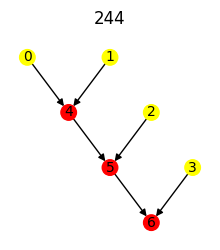

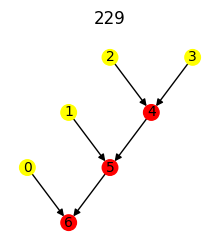

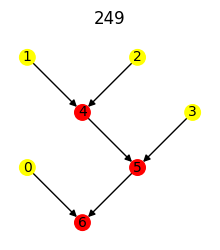

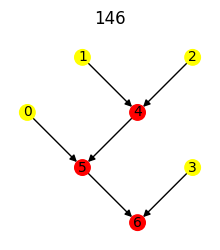

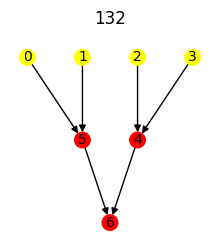

In [41]:
show_hash_map_trees(hash_map)

In [42]:
from functools import reduce

for k in range(2,9):
    k = i
    n_leaves = i
    cat = catalan((2*n_leaves-2)//2)
    
    
    v = i*2-3
      
    spacing = "\t\t" if i < 7 else "\t"
    print(f"n = {i}: Catalan_{i-1} : {cat}")# {spacing} Number of Bifurcating Topologies : {reduce(int.__mul__, range(v, 0, -2))}")

n = 16: Catalan_15 : 9694845
n = 16: Catalan_15 : 9694845
n = 16: Catalan_15 : 9694845
n = 16: Catalan_15 : 9694845
n = 16: Catalan_15 : 9694845
n = 16: Catalan_15 : 9694845
n = 16: Catalan_15 : 9694845


In [18]:
(2*n_leaves-2)//2

255

In [19]:
n_leaves

256

In [20]:
n_leaves + 1

257